In [127]:
# ⭐ Project 6: Employee Attrition Prediction - Decision Tree

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

data = pd.read_csv("employee_attrition_noisy.csv")
df1 = pd.DataFrame(data)
df = df1.copy()
df

,EmployeeID,Age,Gender,MaritalStatus,EducationLevel,JobRole,Department,YearsAtCompany,YearsInCurrentRole,TotalWorkingYears,...,BusinessTravel,DistanceFromHome,OverTime,NumCompaniesWorked,StockOptionLevel,PercentSalaryHike,RemoteWork,ManagerRating,PromotionLast5Years,Attrition
0,522210,39,Male,Married,High School,Senior Analyst,Finance,6,0,18,...,Travel_Frequently,3,No,0,0,22,No,5,No,No
1,863706,35,Female,Divorced,Associate,Customer Success Manager,Customer Support,8,5,10,...,Travel_Frequently,17,Yes,0,0,12,Yes,2,Yes,No
2,869105,43,Female,Married,Master,Brand Analyst,Marketing,10,8,19,...,Travel_Frequently,38,No,1,0,7,No,4,No,No
3,256574,34,Female,Divorced,High School,Brand Analyst,Marketing,5,3,11,...,Travel_Frequently,8,No,2,0,15,No,4,No,No
4,260565,49,Male,Single,PhD,Support Lead,Customer Support,2,0,19,...,Travel_Rarely,8,No,1,1,13,No,3,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15795,635205,37,Male,Single,Associate,Senior Engineer,IT,4,0,12,...,Travel_Rarely,10,No,0,1,11,No,5,No,No
15796,915922,48,Male,Single,High School,HR Specialist,HR,3,0,20,...,Non-Travel,18,No,2,0,23,Yes,4,No,No
15797,455168,36,Male,Single,Bachelor,Supply Chain Analyst,Operations,10,6,13,...,Non-Travel,10,Yes,3,0,16,No,3,No,Yes
15798,655953,38,Female,Married,High School,Accountant,Finance,3,1,15,...,Non-Travel,10,No,0,1,18,No,5,No,No


In [128]:
# EDA process
print(df.head())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())
print(df.isnull().sum())

   EmployeeID  Age  Gender MaritalStatus EducationLevel  \
0      522210   39    Male       Married    High School   
1      863706   35  Female      Divorced      Associate   
2      869105   43  Female       Married         Master   
3      256574   34  Female      Divorced    High School   
4      260565   49    Male        Single            PhD   

                    JobRole        Department  YearsAtCompany  \
0            Senior Analyst           Finance               6   
1  Customer Success Manager  Customer Support               8   
2             Brand Analyst         Marketing              10   
3             Brand Analyst         Marketing               5   
4              Support Lead  Customer Support               2   

   YearsInCurrentRole  TotalWorkingYears  ...     BusinessTravel  \
0                   0                 18  ...  Travel_Frequently   
1                   5                 10  ...  Travel_Frequently   
2                   8                 19  ...  Tra

In [129]:
# Columns Encoding  Categorical data into Numerical data :

#df["Gender"]              = df["Gender"].map({"Male":0,"Female":1})
#df["MaritalStatus"]       = df["MaritalStatus"].map({"Married":0,"Divorced":1,"Single":2})
#df["EducationLevel"]      = df["EducationLevel"].map({"High School":0,"Associate":1,"Master":2,"PhD":3,"Bachelor":4})
#df["OverTime"]            = df["OverTime"].map({"No":0,"Yes":1})
#df["RemoteWork"]          = df["RemoteWork"].map({"No":0,"Yes":1})
#df["PromotionLast5Years"] = df["PromotionLast5Years"].map({"No":0,"Yes":1})

code = LabelEncoder()

columns = ["Gender","MaritalStatus","EducationLevel","JobRole","Department","BusinessTravel","OverTime","RemoteWork","PromotionLast5Years","Attrition"]

for col in columns:
  df[col] = code.fit_transform(df[col])


In [130]:
# Encoded Data Set

df.head()

,EmployeeID,Age,Gender,MaritalStatus,EducationLevel,JobRole,Department,YearsAtCompany,YearsInCurrentRole,TotalWorkingYears,...,BusinessTravel,DistanceFromHome,OverTime,NumCompaniesWorked,StockOptionLevel,PercentSalaryHike,RemoteWork,ManagerRating,PromotionLast5Years,Attrition
0,522210,39,1,1,2,22,1,6,0,18,...,1,3,0,0,0,22,0,5,0,0
1,863706,35,0,0,0,4,0,8,5,10,...,1,17,1,0,0,12,1,2,1,0
2,869105,43,0,1,3,2,4,10,8,19,...,1,38,0,1,0,7,0,4,0,0
3,256574,34,0,0,2,2,4,5,3,11,...,1,8,0,2,0,15,0,4,0,0
4,260565,49,1,2,4,26,0,2,0,19,...,2,8,0,1,1,13,0,3,0,0


In [131]:
# Taking Features In X and Y

x = df.drop(["Attrition","EmployeeID"],axis=1)
y = df["Attrition"]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=42)


In [132]:
# Model Import

model = DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [133]:
# Model Output Testing

y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test,y_pred)

print("The Model Prediction :",y_pred[0])
print(f"The Model Accuracy   : {accuracy*100:.2f}\n")

if y_pred[0] == 0:
  print("*"*40)
  print("The Employee Will Not Leave The Company")
  print("*"*40)
else:
  print("*"*36)
  print("The Employee Will Leave The Company")
  print("*"*36)

The Model Prediction : 0
The Model Accuracy   : 74.21

****************************************
The Employee Will Not Leave The Company
****************************************


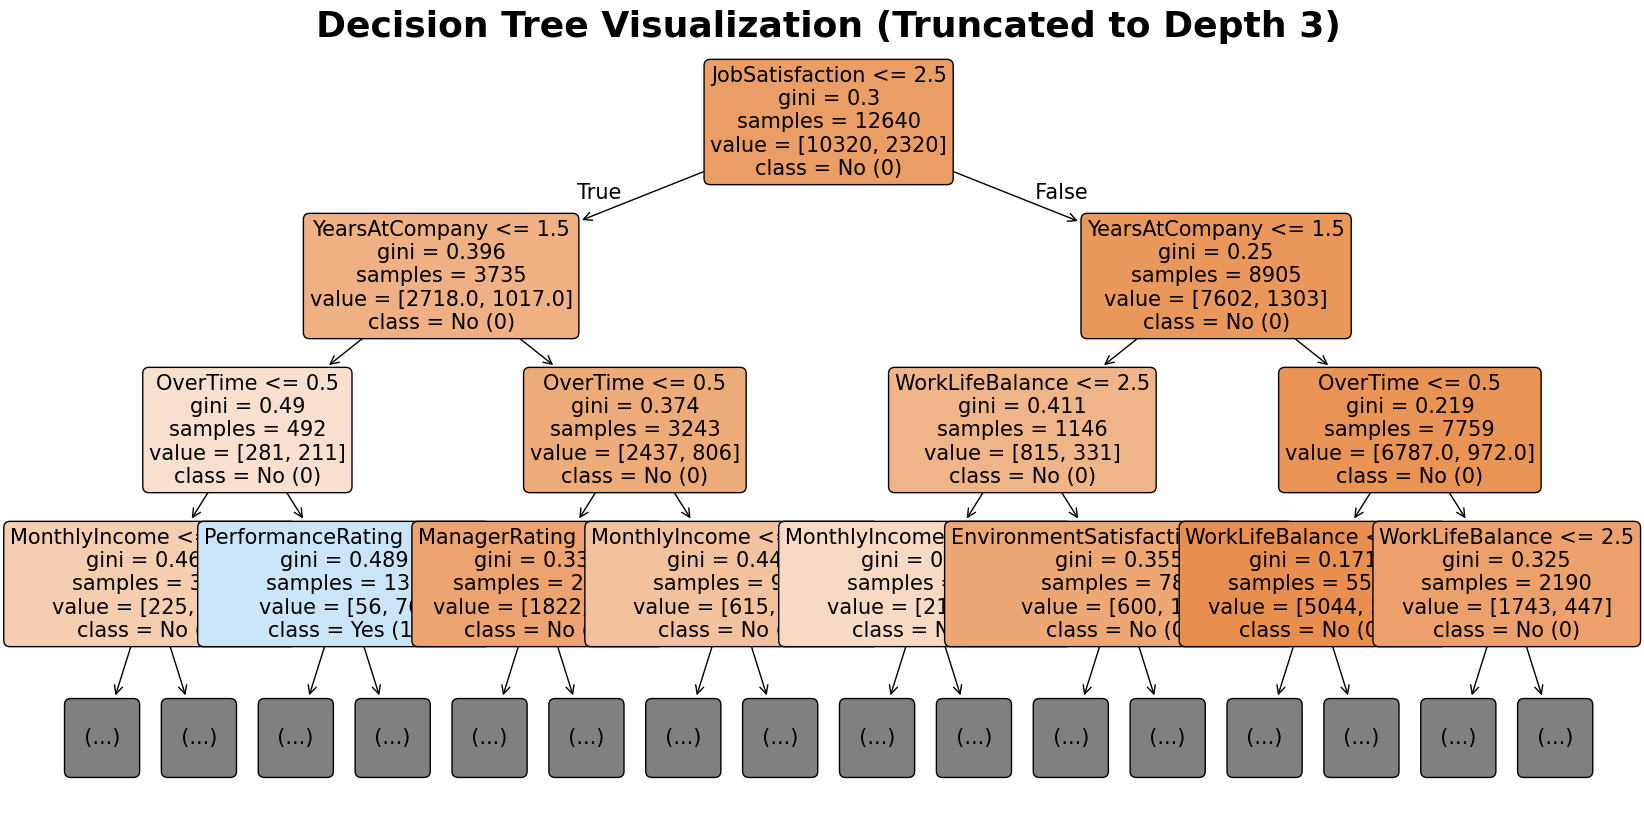

In [134]:
# Plotting a Decision Tree

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(model,max_depth=3,filled=True,rounded=True,
          feature_names=x.columns.tolist(),
          class_names=['No (0)', 'Yes (1)'],fontsize=15)

plt.title("Decision Tree Visualization (Truncated to Depth 3)", fontsize=26, fontweight='bold')
plt.show()